# Product Sale Price Prediction
Predicting `sale_price` for BigBasket products using product metadata (category, brand popularity, rating, market price, etc).

**Corrections made to the original notebook:**
- Added missing imports (`r2_score`, `mean_absolute_error`, `mean_squared_error`, `SGDRegressor`, `DecisionTreeRegressor`, `GradientBoostingRegressor`).
- Fixed two cells that contained real EDA plotting code but were mistakenly typed as Markdown cells (so they never executed).
- Connected the engineered features (`brand_count`, `product_count`, `subcat_count`, one-hot encoded `category`) to the final model input — previously they were computed but never used.
- Removed an unrelated Iris/KNN classification snippet that had nothing to do with this project.
- Fixed train/test scaling leakage: `StandardScaler` is now fit on the training split only.

## 1. Imports

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)

## 2. Load data

In [5]:
df = pd.read_csv('data/raw/BigBasket Products.csv', index_col=False)
df.head()

,index,product,category,sub_category,brand,sale_price,market_price,type,rating,description
0,1,Garlic Oil - Vegetarian Capsule 500 mg,Beauty & Hygiene,Hair Care,Sri Sri Ayurveda,220.0,220.0,Hair Oil & Serum,4.1,This Product contains Garlic Oil that is known...
1,2,Water Bottle - Orange,"Kitchen, Garden & Pets",Storage & Accessories,Mastercook,180.0,180.0,Water & Fridge Bottles,2.3,"Each product is microwave safe (without lid), ..."
2,3,"Brass Angle Deep - Plain, No.2",Cleaning & Household,Pooja Needs,Trm,119.0,250.0,Lamp & Lamp Oil,3.4,"A perfect gift for all occasions, be it your m..."
3,4,Cereal Flip Lid Container/Storage Jar - Assort...,Cleaning & Household,Bins & Bathroom Ware,Nakoda,149.0,176.0,"Laundry, Storage Baskets",3.7,Multipurpose container with an attractive desi...
4,5,Creme Soft Soap - For Hands & Body,Beauty & Hygiene,Bath & Hand Wash,Nivea,162.0,162.0,Bathing Bars & Soaps,4.4,Nivea Creme Soft Soap gives your skin the best...


## 3. Select relevant columns

In [6]:
df = df[['product', 'category', 'sub_category', 'brand', 'sale_price', 'market_price', 'rating']]

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27555 entries, 0 to 27554
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product       27554 non-null  str    
 1   category      27555 non-null  str    
 2   sub_category  27555 non-null  str    
 3   brand         27554 non-null  str    
 4   sale_price    27555 non-null  float64
 5   market_price  27555 non-null  float64
 6   rating        18929 non-null  float64
dtypes: float64(3), str(4)
memory usage: 3.5 MB


In [8]:
for col in df.select_dtypes(exclude='number'):
    print('\n' + col)
    print(df[col].unique())


product
<ArrowStringArray>
[                                        'Garlic Oil - Vegetarian Capsule 500 mg',
                                                          'Water Bottle - Orange',
                                                 'Brass Angle Deep - Plain, No.2',
                        'Cereal Flip Lid Container/Storage Jar - Assorted Colour',
                                             'Creme Soft Soap - For Hands & Body',
                                              'Germ - Removal Multipurpose Wipes',
                                                                   'Multani Mati',
                                              'Hand Sanitizer - 70% Alcohol Base',
 'Biotin & Collagen Volumizing Hair Shampoo + Biotin & Collagen Hair Conditioner',
                                           'Scrub Pad - Anti- Bacterial, Regular',
 ...
                                                             'Acidshoonya Tablet',
                                      'Herbal Rose & A

## 4. Handle missing values

In [9]:
df.isnull().sum()

product            1
category           0
sub_category       0
brand              1
sale_price         0
market_price       0
rating          8626
dtype: int64

In [10]:
# Drop rows with no product/brand identity (can't be meaningfully imputed)
df = df.dropna(subset=['product', 'brand'])

# Impute missing ratings with the column mean
df['rating'] = df['rating'].fillna(df['rating'].mean()).astype(np.float32).round(2)

df.isnull().sum()

product         0
category        0
sub_category    0
brand           0
sale_price      0
market_price    0
rating          0
dtype: int64

## 5. Feature engineering (row level)
Popularity/frequency counts computed on the raw (pre-aggregation) rows: how many listings share the same product name / brand / sub-category.

In [11]:
pcounts = df['product'].value_counts()
df['product_count'] = df['product'].map(pcounts)

bcounts = df['brand'].value_counts()
df['brand_count'] = df['brand'].map(bcounts)

scounts = df['sub_category'].value_counts()
df['subcat_count'] = df['sub_category'].map(scounts)

df.head()

,product,category,sub_category,brand,sale_price,market_price,rating,product_count,brand_count,subcat_count
0,Garlic Oil - Vegetarian Capsule 500 mg,Beauty & Hygiene,Hair Care,Sri Sri Ayurveda,220.0,220.0,4.1,2,12,1028
1,Water Bottle - Orange,"Kitchen, Garden & Pets",Storage & Accessories,Mastercook,180.0,180.0,2.3,1,58,1015
2,"Brass Angle Deep - Plain, No.2",Cleaning & Household,Pooja Needs,Trm,119.0,250.0,3.4,1,42,252
3,Cereal Flip Lid Container/Storage Jar - Assort...,Cleaning & Household,Bins & Bathroom Ware,Nakoda,149.0,176.0,3.7,3,103,392
4,Creme Soft Soap - For Hands & Body,Beauty & Hygiene,Bath & Hand Wash,Nivea,162.0,162.0,4.4,2,87,996


## 6. Aggregate to one row per product
The raw data has multiple rows per product (different pack sizes / listings). We aggregate to a single representative row per product for modeling.

In [12]:
Pdf = df.groupby('product').agg({
    'category': 'first',
    'product_count': 'first',
    'brand_count': 'mean',
    'subcat_count': 'mean',
    'rating': 'mean',
    'market_price': 'mean',
    'sale_price': 'mean'
}).reset_index()

Pdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 23539 entries, 0 to 23538
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   product        23539 non-null  str    
 1   category       23539 non-null  str    
 2   product_count  23539 non-null  int64  
 3   brand_count    23539 non-null  float64
 4   subcat_count   23539 non-null  float64
 5   rating         23539 non-null  float32
 6   market_price   23539 non-null  float64
 7   sale_price     23539 non-null  float64
dtypes: float32(1), float64(4), int64(1), str(2)
memory usage: 2.6 MB


In [13]:
numCol = Pdf[['product_count', 'brand_count', 'subcat_count', 'rating', 'market_price', 'sale_price']]
numCol.describe()

,product_count,brand_count,subcat_count,rating,market_price,sale_price
count,23539.000000,23539.000000,23539.000000,23539.000000,23539.000000,23539.000000
mean,1.170526,68.519141,717.868593,3.934626,387.846133,327.917707
std,0.594302,117.498218,582.845656,0.613443,581.180747,485.876822
min,1.000000,1.000000,1.000000,1.000000,3.000000,3.000000
25%,1.000000,12.000000,274.000000,3.940000,110.000000,99.000000
50%,1.000000,32.000000,643.000000,3.940000,225.000000,198.000000
75%,1.000000,68.000000,996.000000,4.200000,430.000000,362.700000
max,26.000000,638.000000,2294.000000,5.000000,12500.000000,12500.000000


## 7. EDA — distributions

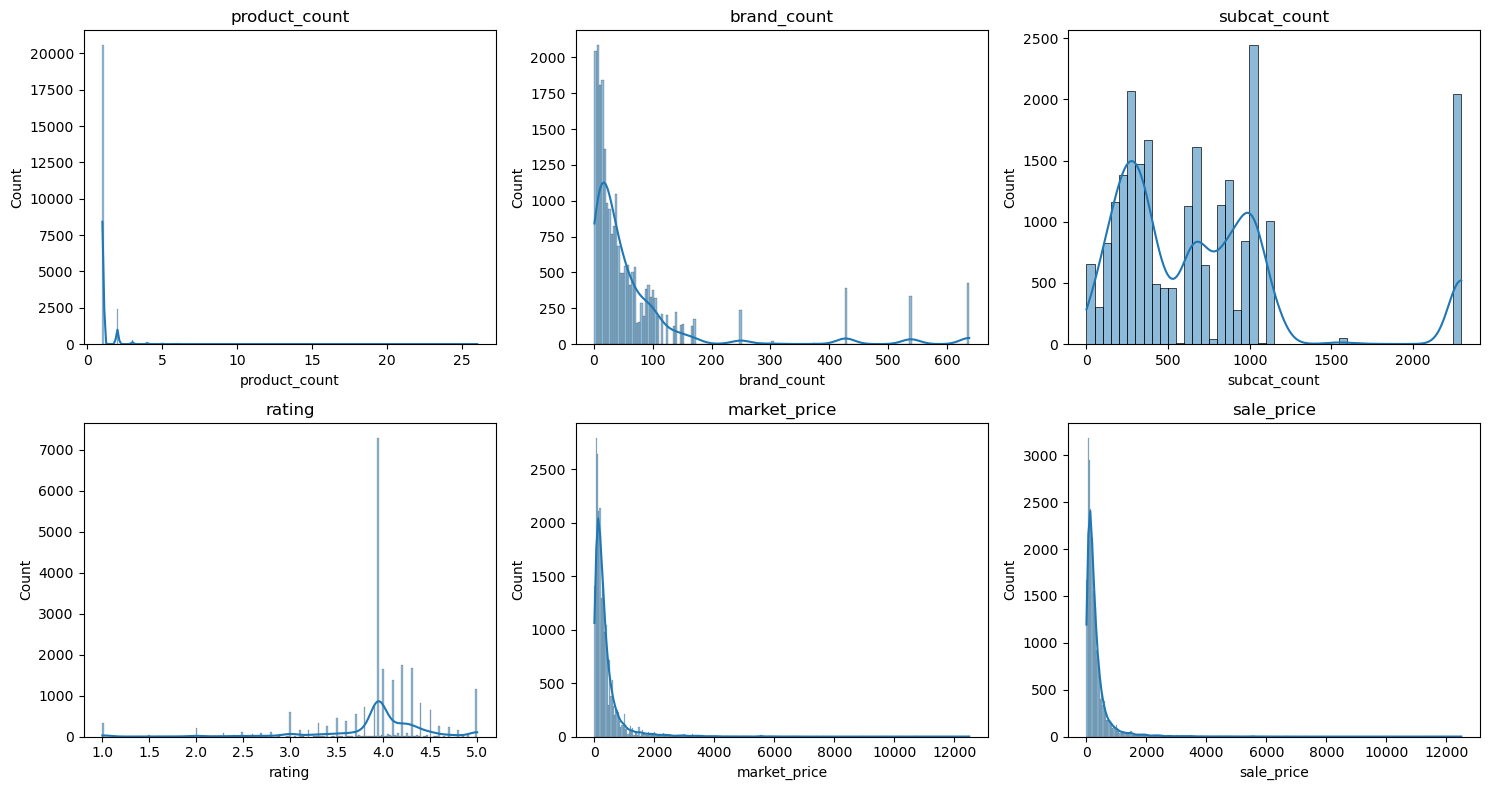

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(numCol.columns):
    sns.histplot(numCol[col], kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

## 8. Log-transform skewed features
`market_price` and `brand_count` are right-skewed; log1p makes their distribution closer to normal, which helps linear models.

In [15]:
Pdf['market_log'] = np.log1p(Pdf['market_price'])
Pdf['brandC_log'] = np.log1p(Pdf['brand_count'])

Pdf = Pdf.drop(columns=['brand_count', 'market_price'])
Pdf.head()

,product,category,product_count,subcat_count,rating,sale_price,market_log,brandC_log
0,& Moms - Citrus Soap,Beauty & Hygiene,1,996.0,4.2,195.00,5.278115,4.564348
1,& Moms - Sandal Soap,Beauty & Hygiene,1,996.0,4.2,108.00,4.795791,4.564348
2,& Moms Bathing Soap - Jasmine,Beauty & Hygiene,1,996.0,4.6,108.00,4.795791,4.564348
3,& Moms Bathing Soap - Tulsi,Beauty & Hygiene,1,996.0,4.4,108.00,4.795791,4.564348
4,0.0 Non Alcoholic Beer,Beverages,1,111.0,4.2,56.25,4.330733,1.098612


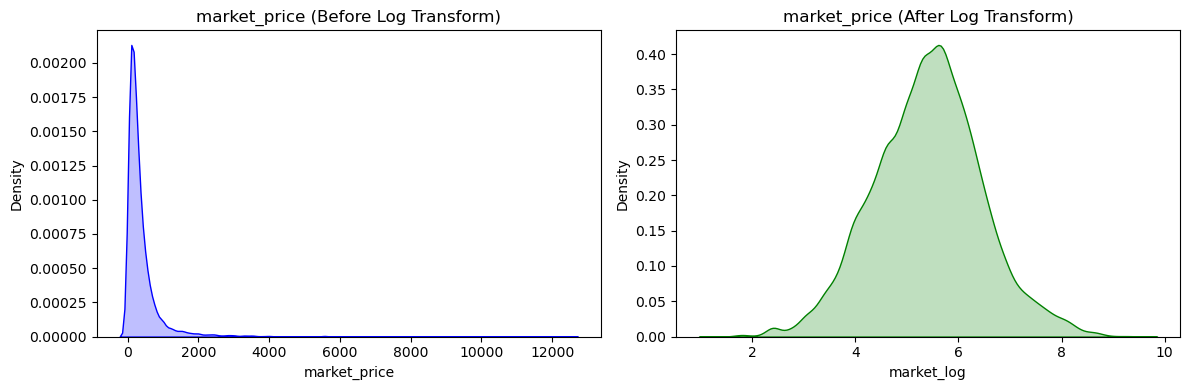

In [16]:
cols = [
    ('market_price', 'market_log'),
]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
sns.kdeplot(df['market_price'].dropna(), ax=axes[0], fill=True, color='blue')
axes[0].set_title('market_price (Before Log Transform)')

sns.kdeplot(Pdf['market_log'].dropna(), ax=axes[1], fill=True, color='green')
axes[1].set_title('market_price (After Log Transform)')

plt.tight_layout()
plt.show()

## 9. Encode categorical feature (`category`)

In [17]:
ohe = OneHotEncoder(sparse_output=False, dtype=np.int32)
encoded = ohe.fit_transform(Pdf[['category']])
cat_df = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(['category']), index=Pdf.index)

new_df = pd.concat([Pdf.drop(columns=['category', 'product']), cat_df], axis=1)
new_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23539 entries, 0 to 23538
Data columns (total 17 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   product_count                      23539 non-null  int64  
 1   subcat_count                       23539 non-null  float64
 2   rating                             23539 non-null  float32
 3   sale_price                         23539 non-null  float64
 4   market_log                         23539 non-null  float64
 5   brandC_log                         23539 non-null  float64
 6   category_Baby Care                 23539 non-null  int32  
 7   category_Bakery, Cakes & Dairy     23539 non-null  int32  
 8   category_Beauty & Hygiene          23539 non-null  int32  
 9   category_Beverages                 23539 non-null  int32  
 10  category_Cleaning & Household      23539 non-null  int32  
 11  category_Eggs, Meat & Fish         23539 non-null  int32  
 12  c

## 10. Build the feature matrix and target
**Fix:** the original notebook engineered `brand_count`, `product_count`, `subcat_count` and one-hot `category`, but then only fed `rating` + `market_log` into the model. We now use the full engineered feature set.

In [18]:
X = new_df.drop(columns=['sale_price'])
y = new_df['sale_price']
X.head()

,product_count,subcat_count,rating,market_log,brandC_log,category_Baby Care,"category_Bakery, Cakes & Dairy",category_Beauty & Hygiene,category_Beverages,category_Cleaning & Household,"category_Eggs, Meat & Fish","category_Foodgrains, Oil & Masala",category_Fruits & Vegetables,category_Gourmet & World Food,"category_Kitchen, Garden & Pets",category_Snacks & Branded Foods
0,1,996.0,4.2,5.278115,4.564348,0,0,1,0,0,0,0,0,0,0,0
1,1,996.0,4.2,4.795791,4.564348,0,0,1,0,0,0,0,0,0,0,0
2,1,996.0,4.6,4.795791,4.564348,0,0,1,0,0,0,0,0,0,0,0
3,1,996.0,4.4,4.795791,4.564348,0,0,1,0,0,0,0,0,0,0,0
4,1,111.0,4.2,4.330733,1.098612,0,0,0,1,0,0,0,0,0,0,0


## 11. Train / test split (before scaling, to avoid leakage)

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 12. Scale continuous features
**Fix:** the scaler is fit on the training data only, then applied to the test data (the original notebook fit the scaler on the full dataset before splitting, which leaks test-set information into training).

Only the continuous columns are scaled; the one-hot category columns are left as 0/1.

In [20]:
continuous_cols = ['product_count', 'subcat_count', 'rating', 'market_log', 'brandC_log']

sc_X = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[continuous_cols] = sc_X.fit_transform(X_train[continuous_cols])
X_test_scaled[continuous_cols] = sc_X.transform(X_test[continuous_cols])

X_train_scaled.head()

,product_count,subcat_count,rating,market_log,brandC_log,category_Baby Care,"category_Bakery, Cakes & Dairy",category_Beauty & Hygiene,category_Beverages,category_Cleaning & Household,"category_Eggs, Meat & Fish","category_Foodgrains, Oil & Masala",category_Fruits & Vegetables,category_Gourmet & World Food,"category_Kitchen, Garden & Pets",category_Snacks & Branded Foods
13989,1.401967,0.312182,-1.677122,1.288567,-0.839317,0,0,1,0,0,0,0,0,0,0,0
22528,-0.287229,2.694699,0.011157,1.170079,-0.769557,0,0,1,0,0,0,0,0,0,0,0
19015,-0.287229,-0.960834,0.011157,-0.430394,-1.000201,0,0,0,0,0,1,0,0,0,0,0
2392,-0.287229,-0.763931,1.731903,-0.091147,-1.880992,0,0,0,0,0,0,0,0,0,0,1
19439,-0.287229,0.479121,-0.378446,-0.115251,0.111234,0,0,1,0,0,0,0,0,0,0,0


## 13. Baseline model — Linear Regression

In [21]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred = lr.predict(X_test_scaled)

print('R2:', r2_score(y_test, y_pred))

R2: 0.518570008436523


## 14. Compare several regression models
**Fix:** `SGDRegressor`, `DecisionTreeRegressor`, `GradientBoostingRegressor`, `mean_absolute_error`, `mean_squared_error` and `r2_score` are now imported (previously used without being imported, which raised `NameError`).

In [22]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "SGD Regressor (Gradient Descent)": SGDRegressor(max_iter=5000, tol=1e-3, random_state=42),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

In [23]:
results = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "RMSE": round(rmse, 4),
        "MAE": round(mae, 4),
        "R2 Score": round(r2, 4),
    })

results_df = pd.DataFrame(results).sort_values('R2 Score', ascending=False).reset_index(drop=True)
results_df

,Model,RMSE,MAE,R2 Score
0,Random Forest,114.5382,36.9633,0.9489
1,Gradient Boosting,120.7805,47.7639,0.9432
2,Decision Tree,142.3904,42.7451,0.9211
3,Linear Regression,351.6321,177.5621,0.5186
4,Ridge,351.6346,177.5491,0.5186
5,SGD Regressor (Gradient Descent),352.4661,174.8787,0.5163


In [24]:
import os
import joblib

model_dir = "models"
os.makedirs(model_dir, exist_ok=True)

# Export each fitted model
for model_name, fitted_model in models.items():
    filename = model_name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    joblib.dump(fitted_model, os.path.join(model_dir, f"{filename}.pkl"))

# Export preprocessing objects and feature metadata
joblib.dump(sc_X, os.path.join(model_dir, "scaler.pkl"))
joblib.dump(continuous_cols, os.path.join(model_dir, "continuous_cols.pkl"))
joblib.dump(list(X.columns), os.path.join(model_dir, "feature_columns.pkl"))

print(f"Exported {len(models)} models and preprocessing files to '{model_dir}/'.")

Exported 6 models and preprocessing files to 'models/'.


## 15. Next steps
This notebook has been split into a repeatable pipeline of standalone scripts (`preprocessing.py`, `eda.py`, `encoding.py`, `model_building.py`, `model_evaluation.py`), each of which reads the previous stage's output and writes its own results to a dedicated output folder.